# Post-Test Praktikum 3: EDA dan Visualisasi Data Monitoring Server

Infrastruktur dan Platform Sains Data

Nama : Mahdiya Rifaya Safa  
NIM : 108102500003


**BAGIAN A**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df_raw = pd.read_csv("data_monitoring_server.csv")
df = df_raw.copy()  

ngambil 5 baris pertama :

In [2]:
df.head()

,log_id,tanggal,server_id,region,tipe_server,cpu_usage,memory_usage,disk_io_mbps,latency_ms,request_count,error_count,uptime_persen,insiden
0,LOG-0038,2024-01-29,SRV-13,Singapura,Compute,76.8,74.7,84.9,126.1,1969.0,2.0,99.79,Ya
1,LOG-0171,2024-03-07,SRV-02,Jakarta,Database,59.0,66.7,227.7,85.9,1483.0,1.0,99.76,Tidak
2,LOG-0257,2024-03-07,SRV-11,Singapura,Web,39.0,57.7,110.7,260.8,1514.0,0.0,99.95,Ya
3,LOG-0061,2024-03-17,SRV-14,Singapura,Web,NaN,50.5,5.0,60.5,738.0,1.0,99.58,Tidak
4,LOG-0154,2024-01-03,SRV-05,Jakarta,Database,58.9,66.6,169.2,65.5,1725.0,3.0,99.74,Tidak


ngambil 5 baris akhir :

In [3]:
df.tail()

,log_id,tanggal,server_id,region,tipe_server,cpu_usage,memory_usage,disk_io_mbps,latency_ms,request_count,error_count,uptime_persen,insiden
303,LOG-0212,2024-03-08,SRV-11,Singapura,Web,24.1,51.0,123.9,49.5,1707.0,3.0,99.83,Tidak
304,LOG-0068,2024-01-29,SRV-06,Surabaya,Web,44.8,60.3,75.5,63.5,1729.0,2.0,99.72,Tidak
305,LOG-0026,2024-01-21,SRV-10,Surabaya,Database,60.3,67.3,177.7,72.9,654.0,2.0,99.54,Tidak
306,LOG-0197,2024-01-11,SRV-06,Surabaya,Web,41.3,58.7,77.8,70.6,1463.0,1.0,99.91,Tidak
307,LOG-0176,2024-03-11,SRV-07,Surabaya,Database,30.1,53.7,223.6,62.6,1208.0,3.0,99.51,Tidak


In [4]:
print("ukuran data (baris, kolom):", df.shape)
print()
df.info()

ukuran data (baris, kolom): (308, 13)

<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   log_id         308 non-null    str    
 1   tanggal        308 non-null    str    
 2   server_id      308 non-null    str    
 3   region         302 non-null    str    
 4   tipe_server    308 non-null    str    
 5   cpu_usage      295 non-null    float64
 6   memory_usage   293 non-null    float64
 7   disk_io_mbps   299 non-null    float64
 8   latency_ms     298 non-null    float64
 9   request_count  308 non-null    float64
 10  error_count    300 non-null    float64
 11  uptime_persen  308 non-null    float64
 12  insiden        308 non-null    str    
dtypes: float64(7), str(6)
memory usage: 31.4 KB


In [5]:
df.describe()

,cpu_usage,memory_usage,disk_io_mbps,latency_ms,request_count,error_count,uptime_persen
count,295.000000,293.000000,299.000000,298.000000,308.000000,300.000000,308.000000
mean,54.157966,64.279863,146.431104,86.715772,1622.324675,1.920000,99.658377
std,15.861565,6.894645,69.188183,41.185232,861.312107,1.383225,0.242401
min,18.100000,46.600000,5.000000,32.100000,454.000000,0.000000,98.750000
25%,43.000000,59.400000,90.000000,66.575000,1299.000000,1.000000,99.550000
50%,54.700000,64.400000,133.100000,82.350000,1541.000000,2.000000,99.720000
75%,64.500000,69.100000,207.850000,94.925000,1815.500000,3.000000,99.840000
max,99.900000,81.900000,337.200000,417.700000,8811.000000,6.000000,100.000000


- numerik : `cpu_usage`, `memory_usage`, `disk_io_mbps`, `latency_ms`, `request_count`, `error_count`, `uptime_persen`
- kategorikal : `server_id`, `region`, `tipe_server`, `insiden`
- pengenal : `log_id`
- tgl : `tanggal`

dari `describe()` udh kelihatan ada yg janggal yaitu `latency_ms`, max nya 417.7 pdhal med nya 82.35, sma `request_count` maxnya 8811 pdahal 75% data dibawah 1815.5

In [6]:
df["tanggal"] = pd.to_datetime(df["tanggal"])
print(df["tanggal"].dtype)

df.info()

datetime64[us]
<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   log_id         308 non-null    str           
 1   tanggal        308 non-null    datetime64[us]
 2   server_id      308 non-null    str           
 3   region         302 non-null    str           
 4   tipe_server    308 non-null    str           
 5   cpu_usage      295 non-null    float64       
 6   memory_usage   293 non-null    float64       
 7   disk_io_mbps   299 non-null    float64       
 8   latency_ms     298 non-null    float64       
 9   request_count  308 non-null    float64       
 10  error_count    300 non-null    float64       
 11  uptime_persen  308 non-null    float64       
 12  insiden        308 non-null    str           
dtypes: datetime64[us](1), float64(7), str(5)
memory usage: 31.4 KB


**BAGIAN B**

B.1 DUPLIKAT

In [7]:
print("jumlah baris sebelum drop_duplicates  :", df.shape[0])
jumlah_dup = df.duplicated().sum()
print("jumlah baris duplikat                 :", jumlah_dup)

jumlah baris sebelum drop_duplicates  : 308
jumlah baris duplikat                 : 8


In [8]:
df = df.drop_duplicates()
print("jumlah baris sesudah drop_duplicates  :", df.shape[0])
print("sisa duplikat                         :", df.duplicated().sum())

jumlah baris sesudah drop_duplicates  : 300
sisa duplikat                         : 0


ada 8 baris yg sama dgn baris lain, bahkan `log_id` nya sama. jadi dupenya dibuang dari versi data yg pertama. jadi datanya turun dri 308 jadi 300 aris.

B.2 NILAI UNIK

log_id           300
tanggal           86
server_id         15
region             3
tipe_server        3
cpu_usage        221
memory_usage     171
disk_io_mbps     268
latency_ms       246
request_count    268
error_count        7
uptime_persen     88
insiden            2
dtype: int64


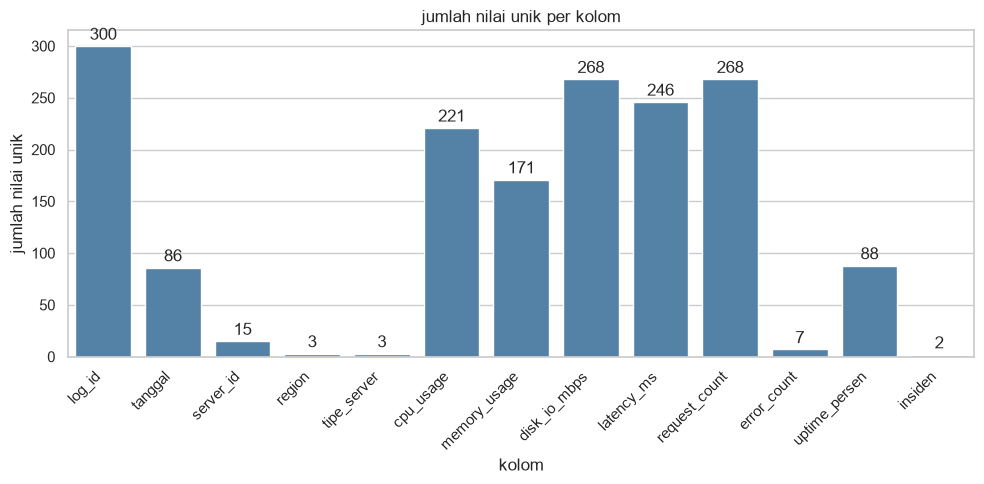

In [9]:
unik = df.nunique()
print(unik)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=unik.index, y=unik.values, color="steelblue")
ax.bar_label(ax.containers[0], padding=2)
plt.title("jumlah nilai unik per kolom")
plt.xlabel("kolom")
plt.ylabel("jumlah nilai unik")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

kolom `log_id` yg berperan jadi pengenal karena punya 300 nilai unik

B.3 NILAI KOSONG

               jumlah kosong  persen (%)
log_id                     0        0.00
tanggal                    0        0.00
server_id                  0        0.00
region                     6        2.00
tipe_server                0        0.00
cpu_usage                 12        4.00
memory_usage              15        5.00
disk_io_mbps               9        3.00
latency_ms                10        3.33
request_count              0        0.00
error_count                8        2.67
uptime_persen              0        0.00
insiden                    0        0.00
total sel kosong: 60


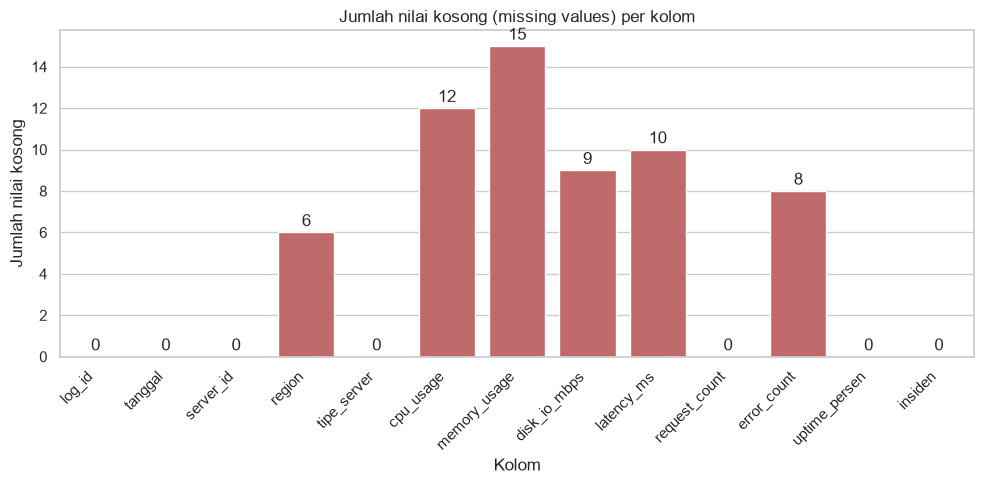

In [10]:
kosong = df.isnull().sum()
persen = (kosong / len(df) * 100).round(2)
tabel_kosong = pd.DataFrame({"jumlah kosong": kosong, "persen (%)": persen})
print(tabel_kosong)
print("total sel kosong:", kosong.sum())

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=kosong.index, y=kosong.values, color="indianred")
ax.bar_label(ax.containers[0], padding=2)
plt.title("Jumlah nilai kosong (missing values) per kolom")
plt.xlabel("Kolom")
plt.ylabel("Jumlah nilai kosong")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

nilai kosong ada 6 kolom, 
- `memory_usage` (15)
- `cpu_usage` (12)
- `latency_ms` (10)
- `disk_io_mbps` (9)
- `error_count` (8)
- `region` (6)

B.4 PENANGANAN NILAI KOSONG

In [11]:
print(df.dropna(subset=["region"]).groupby("server_id")["region"].nunique().max())

1


In [12]:
# kolom numerik -> median
kolom_numerik = df.select_dtypes(include="number").columns
df[kolom_numerik] = df[kolom_numerik].fillna(df[kolom_numerik].median())

# region -> berdasarkan server_id
peta_region = {}
for i in range(1, 16):
    kode = f"SRV-{i:02d}"
    if i <= 5:
        peta_region[kode] = "Jakarta"
    elif i <= 10:
        peta_region[kode] = "Surabaya"
    else:
        peta_region[kode] = "Singapura"

df["region"] = df["region"].fillna(df["server_id"].map(peta_region))

- kenapa yg diisi di kolom yg awalnya dupe tadi di ganti jadi isinya median? bukan rata rata aja? karena ada bbrpa kolom punya nilai ekstrem jadi pake median, karena kalo pake rata rata.. dia nilainya ikut ke tarik ke nilai ekstrem itu, sdgkan median ngga, jadi nilainya lebih ngewakilin kondisi norml server

- `region` dari `server_id`, kenapa makenya server? karena satu server selalu ada di satu region, shg nilai yg jilang bisa dipastiin


B.5 VERIFIKASI

In [13]:
print("jumlah duplikat      :", df.duplicated().sum())
print("total nilai kosong   :", df.isnull().sum().sum())
print("ukuran data bersih   :", df.shape)
print(df.isnull().sum())
print("df_raw tetap utuh    :", df_raw.shape)
print("sel kosong:", df_raw.isnull().sum().sum())

jumlah duplikat      : 0
total nilai kosong   : 0
ukuran data bersih   : (300, 13)
log_id           0
tanggal          0
server_id        0
region           0
tipe_server      0
cpu_usage        0
memory_usage     0
disk_io_mbps     0
latency_ms       0
request_count    0
error_count      0
uptime_persen    0
insiden          0
dtype: int64
df_raw tetap utuh    : (308, 13)
sel kosong: 61


In [14]:

for kolom in ["server_id", "region", "tipe_server", "insiden"]:
    df[kolom] = df[kolom].astype("category")

df.to_csv("data_monitoring_server_bersih.csv", index=False)
df.dtypes

log_id                      str
tanggal          datetime64[us]
server_id              category
region                 category
tipe_server            category
cpu_usage               float64
memory_usage            float64
disk_io_mbps            float64
latency_ms              float64
request_count           float64
error_count             float64
uptime_persen           float64
insiden                category
dtype: object

ringkasan :

1. baris dupe ada 8 jadi dia dibuang, karena log idnya kecatet double
2. kolom kosong di numerik ada 54 sel diisi dgn median kolom, karena median tahan thp nilai ekstrem
3. kosong di `region` ada 6 sel diisi dari `server_id`, karena satu server selalu di satu region


**BAGIAN C**

C. 1 HISTOGRAM

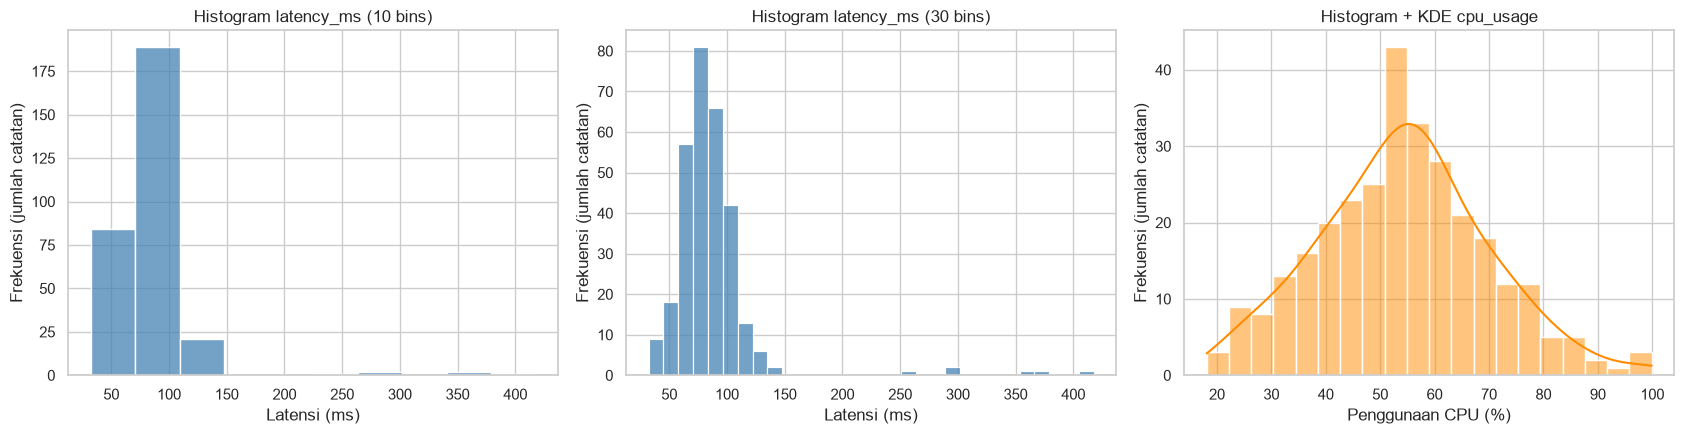

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(data=df, x="latency_ms", bins=10, ax=axes[0], color="steelblue")
axes[0].set_title("Histogram latency_ms (10 bins)")
axes[0].set_xlabel("Latensi (ms)")
axes[0].set_ylabel("Frekuensi (jumlah catatan)")

sns.histplot(data=df, x="latency_ms", bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Histogram latency_ms (30 bins)")
axes[1].set_xlabel("Latensi (ms)")
axes[1].set_ylabel("Frekuensi (jumlah catatan)")

sns.histplot(data=df, x="cpu_usage", bins=20, kde=True, ax=axes[2], color="darkorange")
axes[2].set_title("Histogram + KDE cpu_usage")
axes[2].set_xlabel("Penggunaan CPU (%)")
axes[2].set_ylabel("Frekuensi (jumlah catatan)")

plt.tight_layout()
plt.show()

interpretasi = pada `latency_ms` dgn 10 bins, hampir semua data numpuk di 2 batang pertama shg bentuknya kya keliatan stu tonjolan besar dgn ekor tipis di kanan, detailnya di sekitar puncak hilang. dgn 30 bins puncak terlihat lebih halus dan ekor kanan muncul sebagai batang' kecil yg kpisah dari puncaknya. jadi jumlah bins memengaruhi seberapa rinci bentuk distribusi terlihat. sebaliknya `cpu_usage` hampir simetris seperti lonceng dgn puncak sekiitar 50

C.2 FREKUENSI KATEGORI

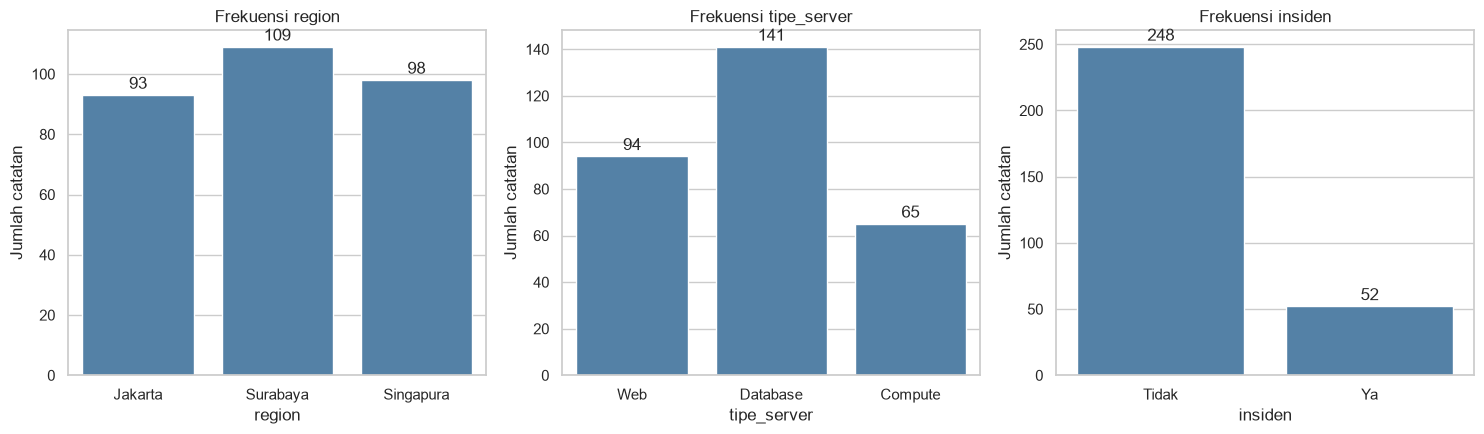

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
urutan = {"region": ["Jakarta", "Surabaya", "Singapura"],
          "tipe_server": ["Web", "Database", "Compute"],
          "insiden": ["Tidak", "Ya"]}

for kolom, ax in zip(["region", "tipe_server", "insiden"], axes):
    sns.countplot(data=df, x=kolom, order=urutan[kolom], ax=ax, color="steelblue")
    ax.bar_label(ax.containers[0], padding=2)
    ax.set_title(f"Frekuensi {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Jumlah catatan")

plt.tight_layout()
plt.show()

frekuensi region
1. sby (109)
2. singapura (98)
3. jakarta(93)

sebarannya cukup seimbang

frekuensi tipe server
1. tipe database (141)
2. web (94)
3. compute (65)

frekuensi insiden
- insiden relatif jarang (52 dri 300)

C.3 MEAN, MEDIAN, DAN SIMPANGAN BAKU

In [19]:
kolom_utama = ["cpu_usage", "latency_ms", "request_count"]
ringkasan = df[kolom_utama].agg(["mean", "median", "std"]).T
ringkasan.columns = ["mean", "median", "simpangan baku"]
ringkasan["mean - median"] = ringkasan["mean"] - ringkasan["median"]
ringkasan

,mean,median,simpangan baku,mean - median
cpu_usage,54.246667,54.45,15.591799,-0.203333
latency_ms,86.690667,82.45,40.908156,4.240667
request_count,1623.833333,1541.00,872.014877,82.833333


In [20]:
print("skewness:")
print(df[kolom_utama].skew().round(2))

skewness:
cpu_usage        0.18
latency_ms       5.06
request_count    6.05
dtype: float64


mean paling jauh dri median pada `request_count` dan `latency_ms`. pada keduanya mean lebih besar dri median, dan skewness-nya positif besar, artinya ada ekor kanan: sebagian kecil nilai yang sangat tinggi menarik mean ke atas. pada `cpu_usage` mean dan median nyaris sama karena distribusinya simetris

selisihnya emg ga besar, tpi simpangan baku `request_count` (sekitar 872) dan `latency_ms` (sekitar 41) ikut membesar gegara nilai" ekstrem tadi. karena itu untuk `latency_ms` dan `request_count` median lebih tepat sebagai ukuran pemusatan, sedangkan untuk `cpu_usage` mean dan median boleh dipakai keduanya

**BAGIAN D**

D.1 BOXPLOT

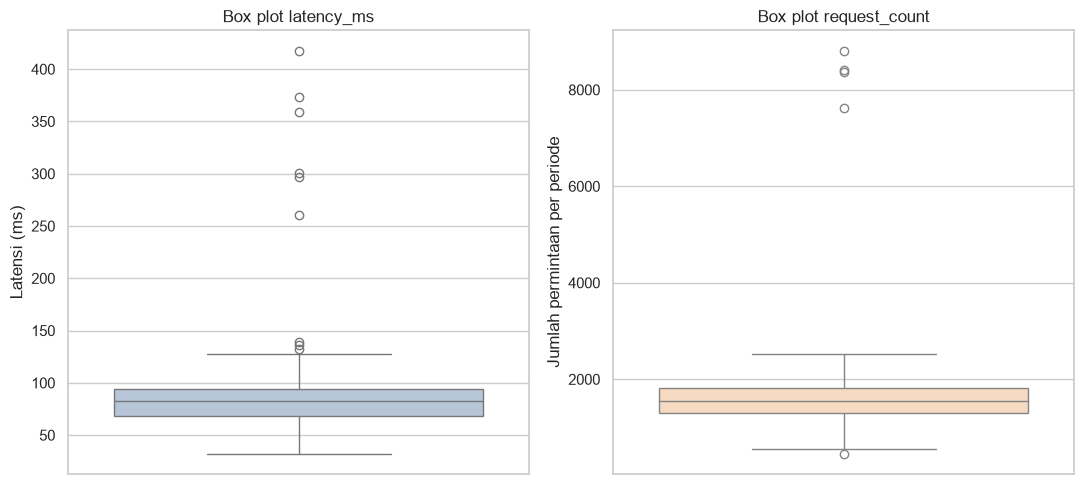

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

sns.boxplot(data=df, y="latency_ms", ax=axes[0], color="lightsteelblue")
axes[0].set_title("Box plot latency_ms")
axes[0].set_ylabel("Latensi (ms)")

sns.boxplot(data=df, y="request_count", ax=axes[1], color="peachpuff")
axes[1].set_title("Box plot request_count")
axes[1].set_ylabel("Jumlah permintaan per periode")

plt.tight_layout()
plt.show()

titik" diluar whisker adlh pengamatan yg jaraknya lebih dri 1.5 kali IQR dri kuartil terdekat jadi nilainya ga lazim dibanding mayoritas data. pada `latency_ms` titik" itu semuanya ada di atas. Pada `request_count` ada beberapa titik yang terpisah jauh di sekitar 7600 sampai 8800, sedangkan kotaknya ada di kisaran 1300 sampai 1800

D.2 BATAS OUTLIER 

In [23]:
q1 = df["latency_ms"].quantile(0.25)
q3 = df["latency_ms"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

print(f"Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f}")
print(f"batas bawah = {batas_bawah:.2f} ms")
print(f"batas atas  = {batas_atas:.2f} ms")

outlier_lat = df[(df["latency_ms"] < batas_bawah) | (df["latency_ms"] > batas_atas)]
print("jumlah outlier latency_ms:", len(outlier_lat))
print("di bawah batas bawah  :", (df["latency_ms"] < batas_bawah).sum())
print("di atas batas atas    :", (df["latency_ms"] > batas_atas).sum())

Q1 = 68.475, Q3 = 93.950, IQR = 25.475
batas bawah = 30.26 ms
batas atas  = 132.16 ms
jumlah outlier latency_ms: 9
di bawah batas bawah  : 0
di atas batas atas    : 9


In [24]:
outlier_lat[["log_id", "tanggal", "server_id", "region", "tipe_server",
             "cpu_usage", "latency_ms", "insiden"]].sort_values("latency_ms", ascending=False)

,log_id,tanggal,server_id,region,tipe_server,cpu_usage,latency_ms,insiden
273,LOG-0253,2024-03-15,SRV-03,Jakarta,Compute,47.8,417.7,Ya
136,LOG-0002,2024-03-15,SRV-12,Singapura,Database,53.8,373.0,Ya
215,LOG-0080,2024-01-24,SRV-11,Singapura,Web,32.1,358.8,Ya
203,LOG-0181,2024-01-26,SRV-15,Singapura,Database,68.3,300.6,Ya
81,LOG-0115,2024-01-02,SRV-08,Surabaya,Compute,77.8,296.8,Ya
2,LOG-0257,2024-03-07,SRV-11,Singapura,Web,39.0,260.8,Ya
96,LOG-0037,2024-03-27,SRV-13,Singapura,Compute,89.8,139.4,Ya
153,LOG-0232,2024-01-15,SRV-13,Singapura,Compute,87.5,136.6,Ya
180,LOG-0166,2024-03-27,SRV-13,Singapura,Compute,92.9,132.3,Ya


batas outlier `latency_ms` adalah 30.26 ms (bawah) dan 132.16 ms (atas). ada 9 outlier, semuanya di atas batas atas (tidak ada yang di bawah batas bawah)

D.3

In [25]:
print("status insiden pada 9 outlier latensi:")
print(outlier_lat["insiden"].value_counts())
print("rata-rata latensi per status insiden:")
print(df.groupby("insiden", observed=True)["latency_ms"].agg(["count", "mean", "median"]).round(1))

status insiden pada 9 outlier latensi:
insiden
Ya       9
Tidak    0
Name: count, dtype: int64
rata-rata latensi per status insiden:
         count   mean  median
insiden                      
Tidak      248   76.3    79.0
Ya          52  136.3   110.2


outlier latensi tetap dipakai. semua 9 outlier ternyata berstatus insiden (insiden = "Ya"), jadi ini bukan cuma salah catat. lonjakan latensi yang muncul justru jadi bagian penting yang perlu dilihat oleh tim SRE. kalo outlier ini dihapus, datanya malah kelihatan lebih normal dari kondisi sebenarnya. dampaknya ke mean tetap dicatat, yaitu sebanyak median yang digunakan untuk ringkasan


In [26]:

qr1, qr3 = df["request_count"].quantile([0.25, 0.75])
batas_atas_req = qr3 + 1.5 * (qr3 - qr1)
lonjakan_req = df[df["request_count"] > batas_atas_req]
print(f"batas atas request_count = {batas_atas_req:.1f}, jumlah di atasnya = {len(lonjakan_req)}")
lonjakan_req[["log_id", "server_id", "tipe_server", "request_count", "latency_ms", "insiden"]]

batas atas request_count = 2590.6, jumlah di atasnya = 4


,log_id,server_id,tipe_server,request_count,latency_ms,insiden
43,LOG-0174,SRV-11,Web,7618.0,66.4,Tidak
60,LOG-0056,SRV-01,Web,8374.0,82.6,Tidak
124,LOG-0090,SRV-13,Compute,8811.0,62.7,Tidak
262,LOG-0020,SRV-07,Database,8412.0,113.6,Ya


untuk `request_count`, ada 4 catatan di atas batas IQR dan nilainya sekitar 5 kali lipat kondisi normal. latensinya pada catatan itu tidak ikut melonjak dan 3 dari 4 bukan insiden. penyebabnya belum bisa dipastikan (bisa lonjakan real trafik, bisa juga kesalahan pencatatan), jadi catatan ini juga ga dibuang dan dicatat sebagai keterbatasan di bagian F

D.4 FILTER DATA

In [27]:
sub = df[(df["region"] == "Singapura") & (df["insiden"] == "Ya")]
print("jumlah baris subset          :", len(sub))
print("rata-rata latency_ms subset  :", round(sub["latency_ms"].mean(), 2), "ms")
print("rata-rata latency_ms seluruh :", round(df["latency_ms"].mean(), 2), "ms")
sub.head()

jumlah baris subset          : 28
rata-rata latency_ms subset  : 142.17 ms
rata-rata latency_ms seluruh : 86.69 ms


,log_id,tanggal,server_id,region,tipe_server,cpu_usage,memory_usage,disk_io_mbps,latency_ms,request_count,error_count,uptime_persen,insiden
0,LOG-0038,2024-01-29,SRV-13,Singapura,Compute,76.8,74.7,84.9,126.1,1969.0,2.0,99.79,Ya
2,LOG-0257,2024-03-07,SRV-11,Singapura,Web,39.0,57.7,110.7,260.8,1514.0,0.0,99.95,Ya
11,LOG-0128,2024-03-13,SRV-12,Singapura,Database,57.4,65.9,147.5,118.5,1488.0,3.0,99.33,Ya
19,LOG-0149,2024-02-16,SRV-13,Singapura,Compute,61.6,67.8,73.3,107.6,1823.0,5.0,99.74,Ya
25,LOG-0291,2024-03-13,SRV-13,Singapura,Compute,65.0,69.4,102.5,115.2,2217.0,6.0,98.92,Ya


ada 28 catatan insiden di singapura dengan rata-rata latensi 142.17 ms. dari 52 insiden yang ada, 28 (lebih dari separuh) terjadi di singapura padahal region ini hanya sekitar sepertiga data

**BAGIAN E**

E.1 SCATTER PLOT CPU VS LATENCY

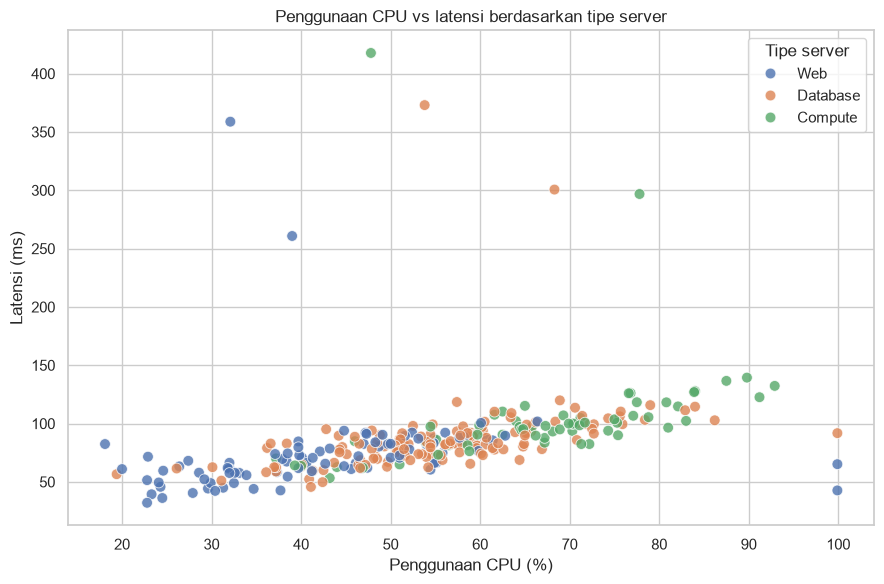

korelasi cpu_usage - latency_ms: 0.33


In [28]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="cpu_usage", y="latency_ms", hue="tipe_server",
                hue_order=["Web", "Database", "Compute"], s=60, alpha=0.8)
plt.title("Penggunaan CPU vs latensi berdasarkan tipe server")
plt.xlabel("Penggunaan CPU (%)")
plt.ylabel("Latensi (ms)")
plt.legend(title="Tipe server")
plt.tight_layout()
plt.show()

print("korelasi cpu_usage - latency_ms:", round(df["cpu_usage"].corr(df["latency_ms"]), 2))

In [29]:
df.groupby("tipe_server", observed=True)[["cpu_usage", "latency_ms"]].mean().round(1)

,cpu_usage,latency_ms
tipe_server,,
Compute,66.4,104.4
Database,55.9,86.7
Web,43.3,74.4


- hubungannya positif tetapi lemah sampai sedang (r = 0.33) makin tinggi CPU, latensi cenderung naik, namun titik-titiknya sangat menyebar
- server web mengelompok di kiri bawah, sedangkan compute berada di kanan dengan latensi paling tinggi, jadi sebagian pola ini berasal dari perbedaan tipe server
- ada juga latensi sangat tinggi pada cpu yang rendah, artinya cpu bukan satu-satunya penyebab lonjakan

E.2 BOXPLOT 

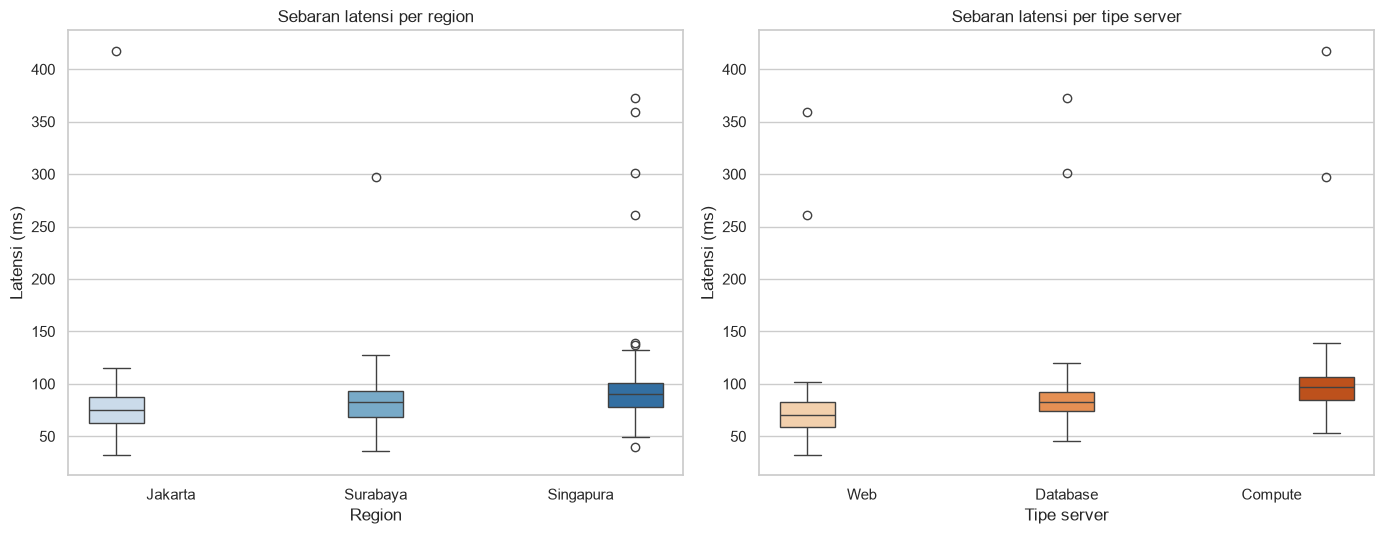

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.boxplot(data=df, x="region", y="latency_ms", order=["Jakarta", "Surabaya", "Singapura"],
            hue="region", hue_order=["Jakarta", "Surabaya", "Singapura"], legend=False,
            ax=axes[0], palette="Blues")
axes[0].set_title("Sebaran latensi per region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Latensi (ms)")

sns.boxplot(data=df, x="tipe_server", y="latency_ms", order=["Web", "Database", "Compute"],
            hue="tipe_server", hue_order=["Web", "Database", "Compute"], legend=False,
            ax=axes[1], palette="Oranges")
axes[1].set_title("Sebaran latensi per tipe server")
axes[1].set_xlabel("Tipe server")
axes[1].set_ylabel("Latensi (ms)")

plt.tight_layout()
plt.show()

In [31]:
for kolom in ["region", "tipe_server"]:
    tabel = df.groupby(kolom, observed=True)["latency_ms"].agg(["count", "mean", "median", "std"]).round(1)
    tabel["persen insiden (%)"] = ((df["insiden"] == "Ya").groupby(df[kolom], observed=True).mean() * 100).round(1)
    print(tabel)
    print()

           count  mean  median   std  persen insiden (%)
region                                                  
Jakarta       93  78.6    74.8  39.5                 5.4
Singapura     98  98.0    89.8  51.4                28.6
Surabaya     109  83.4    82.4  27.4                17.4

             count   mean  median   std  persen insiden (%)
tipe_server                                                
Compute         65  104.4    97.4  50.4                40.0
Database       141   86.7    82.4  34.0                15.6
Web             94   74.4    70.6  39.0                 4.3



berdasarkan median, singapura paling tinggi (89.8 ms) dengan sebaran terlebar (simpangan baku 51.4) dan 28.6% catatannya berstatus insiden, dibanding jakarta 74.8 ms (5.4% insiden) dan surabaya 82.4 ms (17.4%)

berdasarkan tipe, compute paling tinggi (median 97.4 ms, 40% insiden), diikuti Database (82.4 ms) lalu Web (70.6 ms)

jadi kelompok yg paling bermasalah adalah region singapura dan tipe server compute. titik ekstrem 417.7 ms ada di jkarta tapi mediannya ttp pa;ing rendah

E.3 MEAN PLOT

tipe_server
Web          74.4
Database     86.7
Compute     104.4
Name: latency_ms, dtype: float64


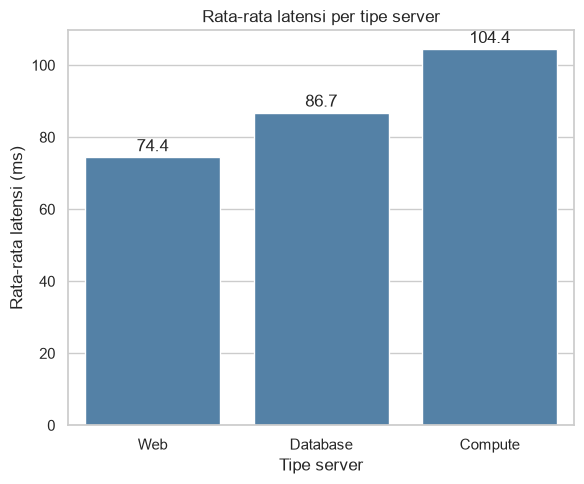

In [32]:
rata_tipe = df.groupby("tipe_server", observed=True)["latency_ms"].mean().reindex(["Web", "Database", "Compute"])
print(rata_tipe.round(1))

plt.figure(figsize=(6, 5))
ax = sns.barplot(x=rata_tipe.index, y=rata_tipe.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=2)
plt.title("Rata-rata latensi per tipe server")
plt.xlabel("Tipe server")
plt.ylabel("Rata-rata latensi (ms)")
plt.tight_layout()
plt.show()

mean plot hanya menampilkan satu angka per kelompok sehingga tidak menunjukkan sebaran maupun outlier, padahal mean sangat dipengaruhi nilai ekstrem. box plot di E2 perlu melengkapinya untuk memperlihatkan median, spread, dan outlier di tiap kelompok

E.4 MATRIKS KORELASI

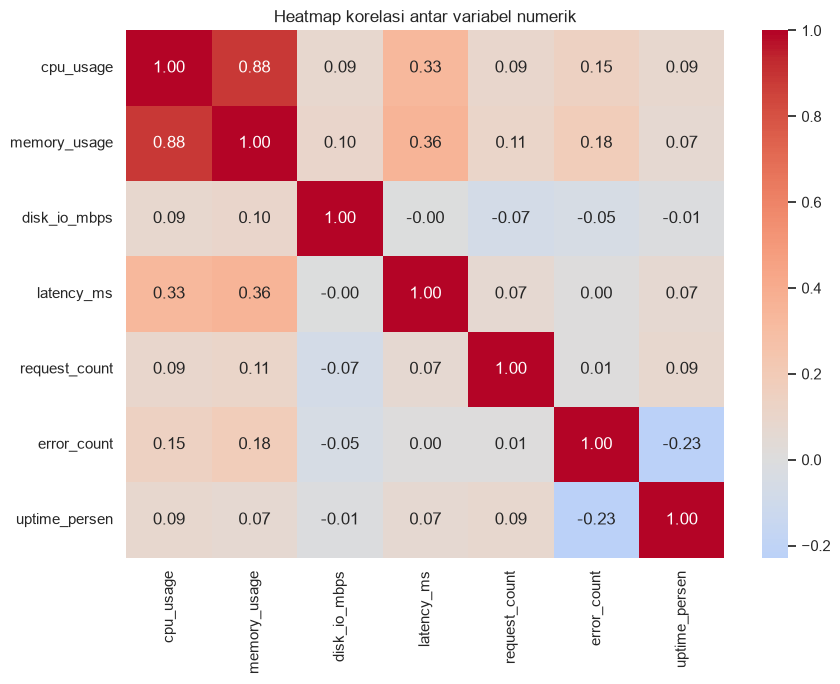

In [33]:
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap korelasi antar variabel numerik")
plt.tight_layout()
plt.show()

In [ ]:

pasangan = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pasangan.abs().sort_values(ascending=False).head(3).round(2))
print()
print("korelasi variabel lain dengan latency_ms:")
print(corr["latency_ms"].drop("latency_ms").sort_values(ascending=False).round(2))

cpu_usage     memory_usage    0.88
memory_usage  latency_ms      0.36
cpu_usage     latency_ms      0.33
dtype: float64

korelasi variabel lain dengan latency_ms:
memory_usage     0.36
cpu_usage        0.33
request_count    0.07
uptime_persen    0.07
error_count      0.00
disk_io_mbps    -0.00
Name: latency_ms, dtype: float64


In [35]:

df_tanpa_lonjakan = df[df["request_count"] <= batas_atas_req]
print("r (semua data)       :", round(df["request_count"].corr(df["latency_ms"]), 2))
print("r (tanpa 4 lonjakan) :", round(df_tanpa_lonjakan["request_count"].corr(df_tanpa_lonjakan["latency_ms"]), 2))

r (semua data)       : 0.07
r (tanpa 4 lonjakan) : 0.19


pasangan terkuat adalah `cpu_usage` dan `memory_usage` (r = 0.88). kaerena proses yg sibuk memakai cpu biasanya jg memegang lebih bnyak memori, shg beban keja yg naik mengangkat 2 2 nya bareng

korelasi  `request_count` dengan `latency_ms` hanya 0.07, tidak ada hub linear. setelah 4 lonjakan `request_count` dikeluarkan nilainya naik ke 0.19 tetapi tetap lemah, jadi kesimpulannya tida berubah. artinya latensi tinggi ga otomatis muncul saat jumlah permintaan bnyak

E.5 INTERPRETASI Q3 & Q4

Q3 = iya, latency berbeda. dari median, singapura lebih tinggi dripada sby dan jakarta, dan tipe compute lebih tinggi dripda database dan web. perbedaan tipe server keliatan lebih jelas dripada perbeedaan region

Q4 = variabel yg paling berkaitan dgn latency adalah `memory_usage` dan `cpu_usage`, keduanya punya hubungan lemah smpe sedang, sedangkan `request_count`, `disk_io_mpbs` dan `error_count` hmpir gaada hubungan. ini cuma korelasi, bukan sebab akibat..

**BAGIAN F**

temuan utama = 
1. data mentah yg isinya 8 baris dupe sma 60 sel kosong, hbs dibenerin sisa 300 baris bersih [bagian B] **Q1**
2. latensi miring ke kanan [D.2 dan D.3] **Q2**
3. latensi tertinggi ada di singapura dan tipe compute, serta berkorelasi dgn memory dan cpu tapi hampir gaada klo sma request [E.2 DAN E.4] **Q3**

rekomendasi =
sebaiknya optimalkan konfigurasi dulu, belum perlu langsung nambah kapasitas karena dari data yang ada, volume request belum kelihatan bikin latensi naik. fokus dulu ke server compute dan region singapura, terutama SRV-13 karena paling sering muncul sebagai outlier. bisa dicek lagi pengaturan cpu dan memorinya. kppasitas baru perlu ditambah kalau setelah optimasi cpu compute latensinya masih tinggi **Q5**

keterbatasan =
data yang dipakai cuma 3 bulan, jadi korelasi belum bisa membuktikan hubungan sebab akibat. selain itu, sekitar 60 sel kosong diisi dengan median sehingga variasi datanya jadi lebih kecil. ada juga 4 lonjakan `request_count` yang belum bisa dipastikan apakah memang trafik asli atau kesalahan pencatatan.